In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
data={
    "AnnualIncome": [15,18,20,22,25,70,75,78,80,85],
    "SpendingScore": [80,85,78,90,82,20,25,15,22,18]

}
df=pd.DataFrame(data)
print(df)

   AnnualIncome  SpendingScore
0            15             80
1            18             85
2            20             78
3            22             90
4            25             82
5            70             20
6            75             25
7            78             15
8            80             22
9            85             18


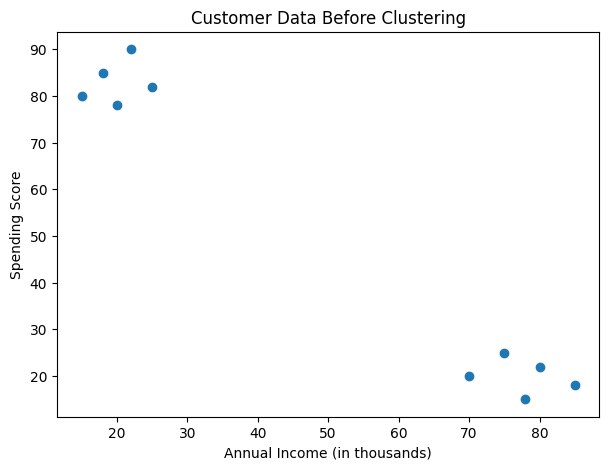

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"]
)
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score")
plt.title("Customer Data Before Clustering")
plt.show()

In [ ]:
X=df[["AnnualIncome","SpendingScore"]]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print(X_scaled.round(2))

[[-1.16  0.9 ]
 [-1.06  1.06]
 [-0.99  0.84]
 [-0.92  1.21]
 [-0.82  0.96]
 [ 0.73 -0.99]
 [ 0.9  -0.84]
 [ 1.   -1.15]
 [ 1.07 -0.93]
 [ 1.24 -1.06]]


In [ ]:
kmeans=KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
kmeans.fit(X_scaled)
df["cluster"]=kmeans.labels_
print(df)

   AnnualIncome  SpendingScore  cluster
0            15             80        0
1            18             85        0
2            20             78        0
3            22             90        0
4            25             82        0
5            70             20        1
6            75             25        1
7            78             15        1
8            80             22        1
9            85             18        1


In [ ]:
centroids_scaled=kmeans.cluster_centers_
centroids_original=scaler.inverse_transform(
    centroids_scaled
)
print("Cluster centroids in original units:")
print(centroids_original.round(2))

Cluster centroids in original units:
[[20.  83. ]
 [77.6 20. ]]


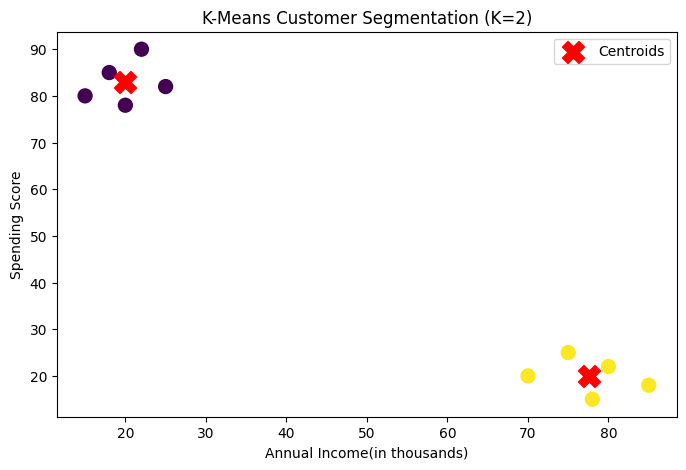

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"],
    c=df["cluster"],
    cmap="viridis",
    s=100
)
plt.scatter(
    centroids_original[:,0],
    centroids_original[:,1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)
plt.xlabel("Annual Income(in thousands)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation (K=2)")
plt.legend()
plt.show()